# Measuring Wealth Inequality in Denmark



# Problem 1.1:

Use Statistics Denmark’s FORMUE16 and FORMUE15. In FORMUE16, one row gives a per-
centile threshold: P10 is the wealth level below which roughly 10% of the group falls, and P50
is the median. In FORMUE15, one row gives the number of people in a wealth bracket.
1. Run the supplied FORMUE16 query. Adapt it to download all wealth brackets from FOR-
MUE15 for 2024, all age groups, nominal prices and the 2020 wealth definition.
2. Inspect the first rows of each result. Which age code denotes all adults? Set the all-adult
rows aside for Part 2 and keep the eight age groups for the age profiles.
Hint. Each keyword in download(...) is one variable code, and ’*’ selects all values. This is the
same information as the variables list in the Lecture 10 API notebook. Open the FORMUE15
table information in your browser to find the variable codes and their values

Link to FORMUE15:
https://api.statbank.dk/v1/tableinfo/FORMUE15?lang=en&format=JSON

For the following exercise we utilize the provided code

## Problem 1.1.1

In [15]:
from io import BytesIO
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(table, **selectors):
    """Download a StatBank table as a DataFrame. Each keyword is one variable code; '*' selects all values."""
    url = f'https://api.statbank.dk/v1/data/{table}/CSV'
    params = dict(lang='en', valuePresentation="Code", **selectors)
    response = requests.get(url, params=params, timeout=45)
    response.raise_for_status()
    frame = pd.read_csv(BytesIO(response.content), sep=';', dtype=str, encoding='utf-8-sig')
    frame = frame.rename(columns={frame.columns[-1]: 'value'})
    frame['value'] = pd.to_numeric(frame['value'].str.replace(',', '.', regex=False))
    return frame

settings = dict(PRISENHED='006', ALDER='*', Tid='2024')  # nominal DKK, all age groups, 2024
percentiles = download('FORMUE16', PERCENTIL='*', **settings)
percentiles.head()

,PERCENTIL,PRISENHED,ALDER,TID,value
0,P1,006,1802,2024,-801501
1,P1,006,1829,2024,-437821
2,P1,006,3039,2024,-1097902
3,P1,006,4049,2024,-1128378
4,P1,006,5059,2024,-968947


In [16]:
settings2 = dict(DEFINITION='D20', ALDER='*', PRISENHED='006', Tid='2024')
wealth = download('FORMUE15', FORMUE='*', **settings2)
wealth.head()

,FORMUE,DEFINITION,ALDER,PRISENHED,TID,value
0,0000M10,D20,1802,006,2024,35488
1,0000M10,D20,1829,006,2024,2199
2,0000M10,D20,3039,006,2024,9488
3,0000M10,D20,4049,006,2024,8438
4,0000M10,D20,5059,006,2024,7737


> 1.1.1 Explanation: 

For the sake of simplicity we will leave out a detailed explanation for why we wish to import the `numpy`, `pandas` and `matplotlib.pyplot` packages - these are already explained in detail in the DataCamp courses. Instead, we pay attention to the package `requests` and `io`. The reason as to why we wish to keep the `requests` package is due to the simplicity that it provides when we wish to retrieve data from an URL. In combination with the `requests` package, the `io` package, specifically `BytesIO`, provides an easy way for python to read raw binary data retrieved from the API, by creating a "pseudo"-like file that python can convert to readable data which we can treat with pandas.  

We observe that the original `def download()` uses two parameters `table` and `**selectors` to retrieve the data and both needs an explanation separately.

First, the `table` parameter is a placeholder parameter, used to define what table python should retrieve from Statbank. We can see from Line 9 that we define `url` as a f-string of Statbanks general API and a variable `{table}`. That is, whenever we use the `download()` function, we define in the first argument the exact table name we wish python to retrieve data from, e.g. FORMUE15 or FORMUE16, which python then manually inserts into the `{table}` part of the API. This corresponds to redirecting python to a table specific API without having to create a new API on Statbank and change the URL all the time.

Secondly the `**selectors` is also a placeholder parameter, used to insert a dictionary with $n$ inputs which we define in the second argument `download()`. This is particularly useful when we use `settings` as a dictionary that stores all necessary table values from the corresponding table. 

From these two observations, we then looked specifically at `settings` and `wealth` to define how python should retrieve the data from the Statbank. Starting with `settings` we defined 5 parameters Formue, Definition, Alder, Prisenhed og Tid to match that of the exercise. We have simplified the code a little, so instead of including 'Formue' in `wealth` function, we put 'Formue' into `**settings`. 

## Problem 1.1.2

In [17]:
percentiles18 = percentiles[percentiles['ALDER'] == '1802']
wealth18 = wealth[wealth['ALDER'] == '1802']

> Explanation 1.1.2

Because "age" is defined in our data retrieval as a code-specific age grouping, we need to search up on [API Statbank](https://api.statbank.dk/console#data) the corresponding codes for all adults with an age greater than or equal to 18 for both FORMUE15 and FORMUE16. We observed that the age groups codes is equivalent for both dataset which simplifies our approach a lot. 

We observed that the corresponding code for all adults with an age greater than or equal to 18 was '1802'. Since we in the `download()` definition, line 10, defined `valuePresentation='Code'` we may utilize this code to filter the age groups by their corresponding group codes. A different approach would've been needed if we instead utilized `valuePresentation='Value'`. 

Because our data retrieval follows the same formatting as Statbank, the filtering method is simple. We first utilize a boolean defined by `percentiles['Alder'] == '1802'` or `wealth['Alder'] == '1802'` to filter statements into either "True" or "False" depending on whether the statement match our required age-group code. Taking the outer operators `percentiles[]` or `wealth[]` converts these true and false statements back into values which is stored respectively as `percentiles18` and `wealth18` for later uses. 

# Problem 1.2: Plot the Age Profiles

1. Draw one figure with age groups along the horizontal axis and three lines for P10, P50 and P90. Label the vertical axis in DKK or million DKK.
2. Within each age group calculate the upper gap (P90 − P50) and the lower gap (P50 − P10). Which age group has the widest upper gap? Give the amount.
3. In which age groups is P10 negative? Give one economic reason why young adults are more likely than older adults to have more debt than assets.

*Hint. Turn the percentile codes into numbers ('P10' becomes 10) with `.str.replace` and `.astype(int)`, as in Lecture 10. Then use `pivot_table` (Lecture 9) to get one row per age group and one column per percentile. The data are one cross-section: you compare different people of different ages in 2024, not the same people as they age.*

## Problem 1.2.1

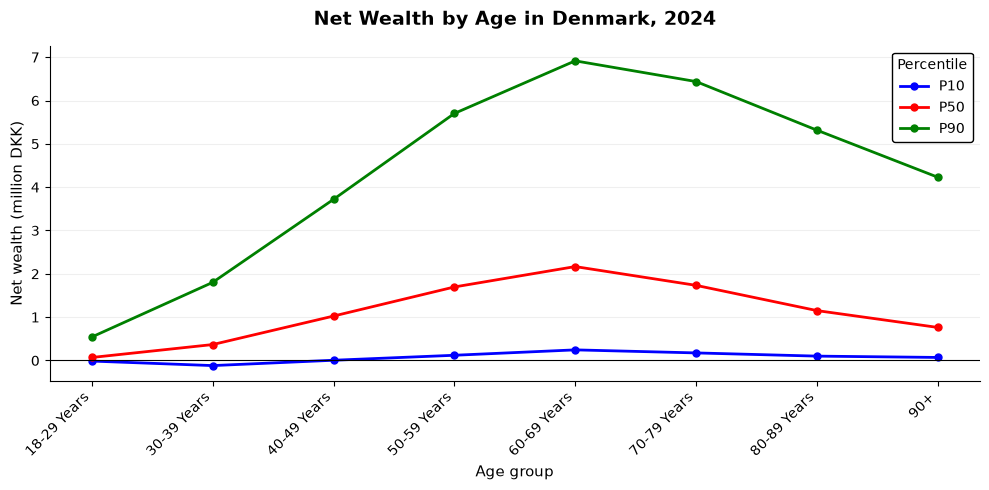

In [18]:
# Define the Age Labels as A Dictionary
age_labels = {
    '1802': 'All adults',
    '1829': '18-29 Years',
    '3039': '30-39 Years',
    '4049': '40-49 Years',
    '5059': '50-59 Years',
    '6069': '60-69 Years',
    '7079': '70-79 Years',
    '8089': '80-89 Years',
    '9099': '90+'
}

# Restructure the percentile data, excluding the all-adult group
age_profiles = percentiles[
    percentiles['ALDER'] != '1802'
].pivot_table(
    index='ALDER',
    columns='PERCENTIL',
    values='value'
)

# Apply age labels and remove the column index name
age_profiles = age_profiles.rename(index=age_labels)
age_profiles.index.name = 'Age'
age_profiles.columns.name = None

# Plot the three selected percentiles
(age_profiles[['P10', 'P50', 'P90']] / 1e6).plot(
    figsize=(10, 5),
    marker='o',
    linewidth=2,
    markersize=5,
    color=["blue","red","green"]
)

# Plotting the Figure
## Title Definition
plt.title('Net Wealth by Age in Denmark, 2024',
          fontsize=14, fontweight='bold', pad=15)

## Label the x-axis
plt.xlabel('Age group', fontsize=11)
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=45, ha='right')

## Define the y-label
plt.ylabel('Net wealth (million DKK)', fontsize=11)

## Allow for grid
plt.grid(axis='y', alpha=0.2)

## Remove top and right Current Axes
plt.gca().spines[['top', 'right']].set_visible(False)

## Define colors and visbility for Legend Box
plt.legend(
    title='Percentile',
    frameon=True,
    edgecolor='black',
    facecolor='white',
    framealpha=1
)

plt.tight_layout()
plt.show()

> Explanation:

To not stray far away from the assignment, we have utilized the dictionary-approach to define the code-specific.

## Problem 1.2.2

In [19]:
age_profiles['Upper gap'] = age_profiles['P90'] - age_profiles['P50']
age_profiles['Lower gap'] = age_profiles['P50'] - age_profiles['P10']

# Display Age as a column without changing age_profiles
age_profiles[['P10', 'P50', 'P90', 'Upper gap', 'Lower gap']].reset_index().style.hide(axis='index').format(precision=0, thousands=',')


Age,P10,P50,P90,Upper gap,Lower gap
18-29 Years,"-14,254","68,806","541,878","473,072","83,060"
30-39 Years,"-118,420","366,935","1,802,110","1,435,175","485,355"
40-49 Years,"4,660","1,024,656","3,718,363","2,693,707","1,019,996"
50-59 Years,"119,753","1,696,187","5,700,964","4,004,777","1,576,434"
60-69 Years,"244,332","2,166,898","6,915,373","4,748,475","1,922,566"
70-79 Years,"174,039","1,733,634","6,437,553","4,703,919","1,559,595"
80-89 Years,"100,122","1,151,164","5,315,410","4,164,246","1,051,042"
90+,"69,644","762,475","4,229,814","3,467,339","692,831"


In [20]:
amount = int(age_profiles['Upper gap'].max())
ageamount = age_profiles['Upper gap'].idxmax()

print(f'The largest spread is {amount:,} DKK which is found at the age group {ageamount}')

The largest spread is 4,748,475 DKK which is found at the age group 60-69 Years


> Explanation 1.2.2:

(Write your explanation here.)

## Problem 1.2.3

In [21]:
# P10 is the wealth level below which the poorest 10% of an age group falls
p10 = age_profiles['P10']

# Keep the age groups where the 10th percentile is strictly below zero
negative_p10 = p10[p10 < 0]

# Report the age groups with a negative P10 together with the amount
print('Age groups with a negative P10 (poorest 10% have more debt than assets):')
if negative_p10.empty:
    print('  None')
for age, value in negative_p10.items():
    print(f'  {age:<12} {value:>12,.0f} DKK')

Age groups with a negative P10 (poorest 10% have more debt than assets):
  18-29 Years       -14,254 DKK
  30-39 Years      -118,420 DKK


> Explanation 1.2.3:

P10 is negative in exactly the two youngest age groups: **18-29 years (-14,254 DKK)** and **30-39 years (-118,420 DKK)**. From 40-49 years onwards P10 is positive and rises to its highest level at 60-69 years, after which it falls again. At least 10% of the youngest adults therefore owe more than they own, whereas even the poorest 10% of older adults have positive net wealth.

One economic reason for this age pattern is the **life-cycle model of saving and borrowing**. Young adults are at the beginning of their working lives, so their current income is low relative to their expected future income. They borrow against that future income to finance human capital (for example SU loans during education), a first car, furniture and a home, and they have not yet had time to build up pension savings or home equity. Older adults have typically repaid their mortgages and accumulated pension and housing wealth, so even the lower tail of their wealth distribution holds positive assets. Because the data are a single cross-section from 2024, the age differences reflect different stages of this life cycle rather than the same people becoming poorer or richer as they age.

In the code we reuse the pivoted `age_profiles` table from Problem 1.2.1, take its `P10` column and keep the rows where P10 is strictly below zero (P10 = 0 would mean the poorest 10% exactly break even, so it is not counted as negative).

# Problem 1.3: Who Has Negative Net Wealth?

Within each age group, divide the number of people in the brackets below zero by the total across all brackets, and express the result as a percentage. Merge the counts and percentages with your percentile table by age. Plot the percentage by age and describe one contrast with the median profile. Check that the eight age counts sum to the published all-adult count.

*Hint. Three brackets lie below zero; identify them from the bracket labels in the table information. `groupby` sums counts by age, and `pd.merge(..., validate='1:1')` checks that each age group appears once (Lecture 10).*

In [22]:
# The three wealth brackets that lie below zero (from the FORMUE15 table information)
negative_brackets = ['0000M10', 'M100M05', 'M050000']

# Total number of people and number with negative wealth in each of the eight age groups
adult_groups = wealth['ALDER'] != '1802'
age_totals = wealth.loc[adult_groups].groupby('ALDER')['value'].sum()
negative_totals = (
    wealth.loc[adult_groups & wealth['FORMUE'].isin(negative_brackets)]
    .groupby('ALDER')['value']
    .sum()
)

# Counts and percentages in one table, using the same age labels as age_profiles
negative_share = pd.DataFrame({
    'Negative count': negative_totals,
    'Total count': age_totals,
})
negative_share['Negative share (%)'] = 100 * negative_share['Negative count'] / negative_share['Total count']
negative_share = negative_share.rename(index=age_labels)
negative_share.index.name = 'Age'

# Merge onto the percentile table; validate='1:1' checks one row per age group
merged = age_profiles.reset_index().merge(
    negative_share.reset_index(),
    on='Age',
    validate='1:1',
)

# Check that the eight age groups sum to the published all-adult count
published_all_adults = wealth.loc[wealth['ALDER'] == '1802', 'value'].sum()
summed_age_groups = wealth.loc[adult_groups, 'value'].sum()
print(f'Sum of eight age groups: {summed_age_groups:,.0f}')
print(f'Published all adults:    {published_all_adults:,.0f}')
print(f'Difference:              {summed_age_groups - published_all_adults:,.0f}')

# Show the merged table
merged[['Age', 'P10', 'P50', 'P90', 'Negative count', 'Total count', 'Negative share (%)']].style.hide(axis='index').format({
    'P10': '{:,.0f}',
    'P50': '{:,.0f}',
    'P90': '{:,.0f}',
    'Negative count': '{:,.0f}',
    'Total count': '{:,.0f}',
    'Negative share (%)': '{:.1f}',
})

Sum of eight age groups: 4,851,818
Published all adults:    4,851,818
Difference:              0


Age,P10,P50,P90,Negative count,Total count,Negative share (%)
18-29 Years,"-14,254","68,806","541,878","112,690","927,354",12.2
30-39 Years,"-118,420","366,935","1,802,110","122,087","783,901",15.6
40-49 Years,"4,660","1,024,656","3,718,363","62,699","708,080",8.9
50-59 Years,"119,753","1,696,187","5,700,964","41,209","802,113",5.1
60-69 Years,"244,332","2,166,898","6,915,373","21,947","709,729",3.1
70-79 Years,"174,039","1,733,634","6,437,553","17,437","581,304",3.0
80-89 Years,"100,122","1,151,164","5,315,410","8,636","291,975",3.0
90+,"69,644","762,475","4,229,814",886,"47,362",1.9


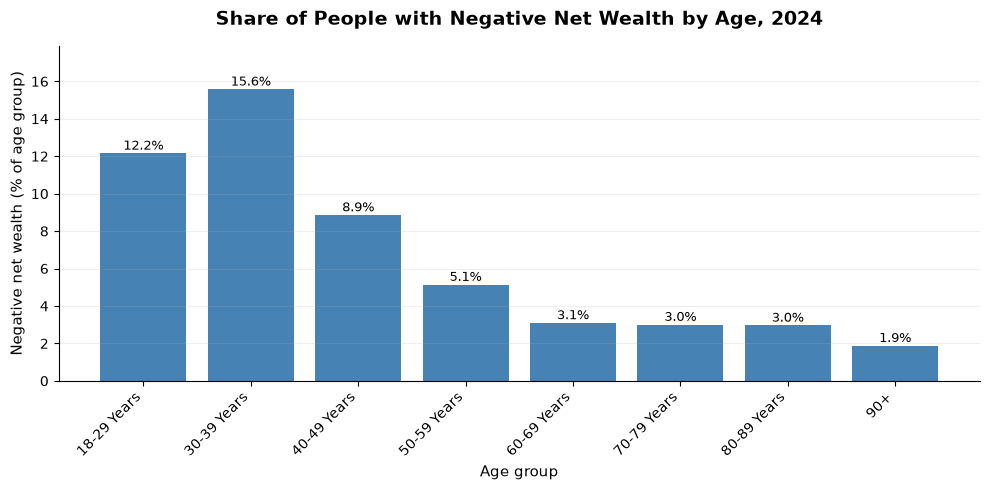

In [23]:
# Percentage with negative net wealth by age group
plt.figure(figsize=(10, 5))
plt.bar(merged['Age'], merged['Negative share (%)'], color='steelblue')

# Title and axis labels
plt.title('Share of People with Negative Net Wealth by Age, 2024',
          fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Age group', fontsize=11)
plt.ylabel('Negative net wealth (% of age group)', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.ylim(0, merged['Negative share (%)'].max() * 1.15)
plt.grid(axis='y', alpha=0.2)
plt.gca().spines[['top', 'right']].set_visible(False)

# Write the percentage above each bar
for age, share in zip(merged['Age'], merged['Negative share (%)']):
    plt.text(age, share + 0.2, f'{share:.1f}%', ha='center', fontsize=9)

plt.tight_layout()
plt.show()

> Explanation 1.3:

The three brackets below zero are 'Under (-1.000.000 DKK)', '(-1.000.000 DKK) - (-500.000 DKK)' and '(-500.000 DKK) - 0 DKK' (codes `0000M10`, `M100M05` and `M050000`). We sum the counts in these three brackets within each age group and divide by the group's total count across all 16 brackets. The result is merged with the percentile table on age using `validate='1:1'`, which confirms that every age group occurs exactly once on both sides.

The share with negative net wealth is highest at **30-39 years (15.6%)**, where 122,087 of 783,901 people have more debt than assets, and lowest at **90+ years (1.9%)**. It falls steadily after the 30s: 8.9% at 40-49, 5.1% at 50-59 and around 3% from 60 to 79. For all adults the share is 8.0%, so the age profile is driven by the young.

**Contrast with the median profile:** median net wealth is lowest at 18-29 years (68,806 DKK) and peaks at 60-69 years (2,166,898 DKK), whereas the negative share peaks one age group later, at 30-39, and is already lower at 18-29 (12.2%). A low median therefore does not mean widespread debt: most 18-29-year-olds have few assets but also few large liabilities, while the 30s are when people typically buy their first home with a mortgage, start a family and take on consumer debt. Debt thus becomes more common even though median wealth is higher. Median wealth falls again from 60-69 to 90+, but the negative share falls as well, because the elderly have largely repaid their mortgages and hold pension and housing assets.

The sum check confirms that the eight age groups contain 4,851,818 people in total, exactly the published all-adult count (difference 0), so the age counts are consistent with the all-adult row.